# 02 · CITES Trade Database: what the data looks like

Exploratory analysis of the **CITES Trade Database full download** (UNEP-WCMC for the CITES Secretariat, v2026.1), as published and before any alignment with LEMIS.

**Why this notebook exists.** Before deciding how LEMIS and CITES are aligned, we need to know what CITES actually contains: what one record is, how often the same trade is reported twice, what is blank and what blank means, and how products, units and taxa are recorded. Each finding ends in what CITES needs before scoring and what it means for alignment with LEMIS. Notebook 01 does the same for LEMIS, and notebook 03 compares the two.

**What it takes as given.** Only the publishers' rules for reading the files, recorded in [`DATA/USING_LEMIS_AND_CITES.md`](../../DATA/USING_LEMIS_AND_CITES.md) and cited below as *guide §x*. Nothing here assumes an alignment rule. The rules for WildGuard's alignment were written afterwards from these findings, in [`DATA/ALIGNING_LEMIS_AND_CITES.md`](../../DATA/ALIGNING_LEMIS_AND_CITES.md).

Its findings feed report §3 (data) and §3.4 (schema alignment).

**Reading rules applied throughout** (guide §2.2): animals are records with a `Class` (plants have none). The **scoring window** is animal records from 2015–2024, the years after LEMIS ends. The same trade can be reported twice, by the exporter (`E`) and by the importer (`I`), so every count below says which reporter type it covers. Appendix `N` is not a CITES listing: it is shown once and then excluded.

In [1]:
import glob
import re
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

import eda_setup as E
from eda_setup import config

E.style()
con = E.connect()


def Q(sql):
    return E.q(con, sql)


def pct(s):
    return (100 * s).round(2).astype(str) + "%"


# the scoring window without Appendix N, used from section 4 on
con.execute("CREATE VIEW win AS SELECT * FROM cites_window WHERE Appendix <> 'N'")

## 1. File identity

The version is stated only in the release notes shipped inside the zip (guide §2.1).

In [2]:
info = glob.glob(config.RAW_CITES_INFO_GLOB)[0]
xml = zipfile.ZipFile(info).read("word/document.xml").decode()
text = re.sub(r"<[^>]+>", "", xml.replace("</w:p>", "\n"))
for line in text.splitlines():
    if re.search(r"Version|extracted|received", line):
        print("•", line.strip()[:400])

• Recommended citation: Full CITES Trade Database Download. Version 2026.1. Compiled by UNEP-WCMC, Cambridge, UK for the CITES Secretariat, Geneva, Switzerland. Available at: trade.cites.org.
• This zip file contains all trade records (including all historic data) contained in the CITES Trade Database and extracted at the shipment level on 9 June 2026; this includes data from CITES annual reports and any updates that were received by UNEP-WCMC by 5 May 2026. This file is 2026.v1. Please note that some historic records present in previous versions may also have been removed or updated (e.


In [3]:
csvs = glob.glob(config.RAW_CITES_GLOB)
pd.Series({
    "CSV files": len(csvs),
    "records": f"{Q('SELECT count(*) FROM cites').iat[0, 0]:,}",
    "unique Id": f"{Q('SELECT count(DISTINCT Id) FROM cites').iat[0, 0]:,}",
    "years": tuple(Q("SELECT min(Year), max(Year) FROM cites").iloc[0]),
    "columns": ", ".join(Q("DESCRIBE cites_raw")["column_name"]),
}, name="CITES").to_frame()

,CITES
CSV files,59
records,"29,170,051"
unique Id,"29,170,051"
years,"(1975, 2026)"
columns,"Id, Year, Appendix, Taxon, Class, Order, Famil..."


## 2. What one row is, and how many there are

One row is one line item of a permit or certificate, **as reported by one Party** (guide §2.2).

In [4]:
Q("""SELECT CASE WHEN Class IS NULL THEN 'plants (no Class)' ELSE 'animals' END AS kingdom,
            count(*) AS records,
            count(*) FILTER (WHERE "Reporter.type" = 'E') AS exporter_reported,
            count(*) FILTER (WHERE "Reporter.type" = 'I') AS importer_reported
     FROM cites GROUP BY 1 ORDER BY 1""")

,kingdom,records,exporter_reported,importer_reported
0,animals,20962017,12040995,8921022
1,plants (no Class),8208034,5637947,2570087


,E,I,total
Year,,,
2012,564193,345895,910088
2013,590829,348454,939283
2014,563670,354209,917879
2015,609378,371180,980558
2016,582979,366464,949443
2017,563078,345237,908315
2018,496922,351293,848215
2019,477940,345045,822985
2020,388966,278863,667829


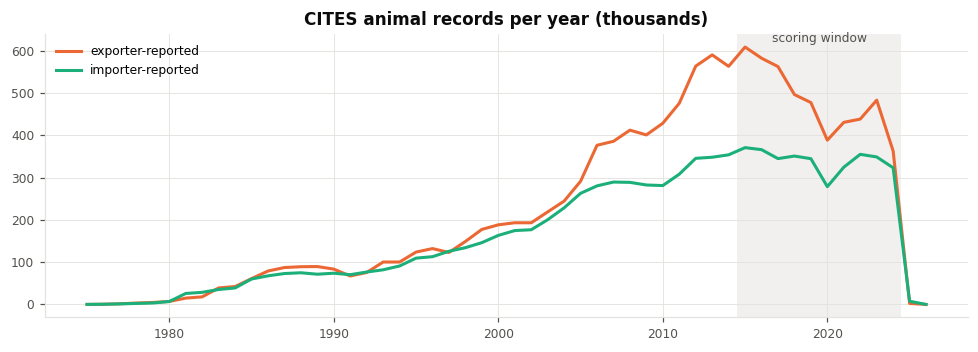

In [5]:
per_year = Q("""SELECT Year, count(*) FILTER (WHERE "Reporter.type" = 'E') AS E,
                       count(*) FILTER (WHERE "Reporter.type" = 'I') AS I, count(*) AS total
                FROM cites_animals GROUP BY 1 ORDER BY 1""").set_index("Year")
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.axvspan(2014.5, 2024.5, color=E.GRID, alpha=0.5, lw=0)
ax.text(2019.5, per_year.E.max() / 1e3 * 1.02, "scoring window", ha="center", fontsize=8, color=E.INK_2)
ax.plot(per_year.index, per_year.E / 1e3, color=E.CITES_C, label="exporter-reported")
ax.plot(per_year.index, per_year.I / 1e3, color=E.THIRD_C, label="importer-reported")
ax.set_title("CITES animal records per year (thousands)")
ax.legend(loc="upper left")
fig.tight_layout()
per_year.loc[2012:]

Annual reports are due by 31 October of the following year, so the last two years are incomplete (guide §2.2). Records in the scoring window:

In [6]:
Q("""SELECT count(*) AS records,
            count(*) FILTER (WHERE "Reporter.type" = 'E') AS exporter_reported,
            count(*) FILTER (WHERE "Reporter.type" = 'I') AS importer_reported,
            count(*) FILTER (WHERE Appendix = 'N') AS appendix_N
     FROM cites_window""").rename(index={0: "animals 2015-2024"})

,records,exporter_reported,importer_reported,appendix_N
animals 2015-2024,8247093,4836000,3411093,6511


## 3. Appendix

`N` marks non-CITES species reported by EU members under stricter domestic measures. It is not a CITES listing (guide §2.2).

In [7]:
Q("""SELECT Appendix, count(*) AS records FROM cites_window GROUP BY 1 ORDER BY 1""").pipe(
    E.share, "records")

,Appendix,records,share
0,I,402768,4.88%
1,II,7736555,93.81%
2,III,101259,1.23%
3,N,6511,0.08%


## 4. Missing values

Within the scoring window (Appendix N excluded, both reporter types):

In [8]:
cols = Q("DESCRIBE win")["column_name"].tolist()
n_win = Q("SELECT count(*) FROM win").iat[0, 0]
nulls = Q("SELECT " + ", ".join(f'count(*) FILTER (WHERE "{c}" IS NULL) AS "{c}"' for c in cols)
          + " FROM win").T[0]
pd.DataFrame({"missing": nulls, "share": pct(nulls / n_win)}).query("missing > 0").sort_values(
    "missing", ascending=False)

,missing,share
Ifs.permit.RandomID,8240195,100.0%
Import.permit.RandomID,6745608,81.86%
Origin.permit.RandomID,4608685,55.93%
Unit,4258036,51.67%
Origin,2756121,33.45%
Export.permit.RandomID,262885,3.19%
Genus,86568,1.05%
Family,63743,0.77%
Source,12070,0.15%
Purpose,10763,0.13%


A blank `Origin` means the exporter is the origin (direct trade) or that origin was not reported. A blank `Unit` means a count, like `Number of specimens`. A blank `Genus` means the record was reported above genus level (section 7).

**Permit IDs.** The export permit ID is almost always present (missing in 3.2%). The import permit ID is mostly blank (81.9%), because exporters do not report it, and the origin permit is filled only for re-exports. The IDs are random replacements for the real permit numbers, but the same permit always gets the same ID (guide §2.1). So the export permit ID can link records across reporters, which notebook 05 uses.

## 5. Purpose and source

In [9]:
def mix(col, labels):
    df = Q(f"""SELECT {col} AS code,
                      count(*) FILTER (WHERE "Reporter.type" = 'E') AS exporter_reported,
                      count(*) FILTER (WHERE "Reporter.type" = 'I') AS importer_reported
               FROM win GROUP BY 1 ORDER BY 2 DESC""")
    df.insert(1, "meaning", df.code.map(labels))
    for r in ["exporter_reported", "importer_reported"]:
        df[f"{r[:8]} share"] = pct(df[r] / df[r].sum())
    return df

mix("Purpose", E.CITES_PURPOSE)

,code,meaning,exporter_reported,importer_reported,exporter share,importer share
0,T,commercial,4369647,3052290,90.37%,89.64%
1,P,personal,147528,113350,3.05%,3.33%
2,H,hunting trophy,146671,139121,3.03%,4.09%
3,M,medical / biomedical,109461,39194,2.26%,1.15%
4,S,scientific,24833,23402,0.51%,0.69%
5,Z,zoo,11420,11250,0.24%,0.33%
6,Q,circus / travelling exhibition,11151,7763,0.23%,0.23%
7,B,breeding,5950,7297,0.12%,0.21%
8,None,NaN,3710,7053,0.08%,0.21%
9,E,educational,2588,2754,0.05%,0.08%


In [10]:
mix("Source", E.CITES_SOURCE)

,code,meaning,exporter_reported,importer_reported,exporter share,importer share
0,W,wild,2924055,2144370,60.47%,62.98%
1,C,bred in captivity,1194468,733270,24.7%,21.53%
2,F,born in captivity (F1+),325431,225017,6.73%,6.61%
3,R,ranched,265211,174648,5.48%,5.13%
4,D,"commercially bred (App. I, registered operations)",77452,57834,1.6%,1.7%
5,O,pre-Convention,36279,25670,0.75%,0.75%
6,None,NaN,4879,7191,0.1%,0.21%
7,U,unknown,3831,3041,0.08%,0.09%
8,I,confiscated or seized specimen,2684,30272,0.06%,0.89%
9,X,marine environment outside any State's jurisdi...,1253,3725,0.03%,0.11%


Source `I` is **not a seizure**. It marks the legal, permitted movement of an item that was seized earlier, for example its return to the country of origin. Seizures themselves are in the separate, access-restricted CITES Illegal Trade Database (guide §2.2).

## 6. Product terms and units

In [11]:
Q("""SELECT (SELECT count(DISTINCT Term) FROM cites) AS terms_all_records,
            (SELECT count(DISTINCT Term) FROM cites_animals) AS terms_animals_all_years,
            (SELECT count(DISTINCT Term) FROM win) AS terms_scoring_window""")

,terms_all_records,terms_animals_all_years,terms_scoring_window
0,115,101,81


In [12]:
Q("""SELECT Term, count(*) AS records, count(DISTINCT coalesce(Unit, 'Number of specimens')) AS units
     FROM win GROUP BY 1 ORDER BY 2 DESC LIMIT 25""").pipe(E.share, "records")

,Term,records,units,share
0,leather products (small),4452778,8,54.51%
1,live,1986037,6,24.31%
2,skins,359285,10,4.4%
3,specimens,223152,13,2.73%
4,trophies,203323,5,2.49%
5,caviar,168813,7,2.07%
6,raw corals,114390,7,1.4%
7,garments,114030,6,1.4%
8,skin pieces,95921,7,1.17%
9,cosmetics,76928,7,0.94%


In [13]:
Q("""SELECT coalesce(Unit, '(blank)') AS Unit, count(*) AS records,
            quantile_cont(Quantity, 0.5) AS median, quantile_cont(Quantity, 0.99) AS p99,
            max(Quantity) AS max, count(*) FILTER (WHERE Quantity = 0) AS zero_qty
     FROM win GROUP BY 1 ORDER BY 2 DESC""")

,Unit,records,median,p99,max,zero_qty
0,(blank),4258036,4,932,"120,000,000",0
1,Number of specimens,3456718,2,900,"5,000,000",0
2,kg,286342,12,"20,410","3,000,000",0
3,g,127046,2.797,4.318e+04,"500,000,000",0
4,ml,81669,4,"1,000","264,845",0
5,mg,22313,248,1.137e+06,"191,000,000",0
6,m2,6286,0.79,143.4,"49,725",0
7,l,747,3,"8,528","20,000",0
8,m,694,19.24,"2,000","4,000",0
9,microgrammes,395,2.968e+04,1.777e+08,"800,000,000",0


**One term, several units.** Quantities in different units cannot be compared, and different terms are not comparable either: one feather is not one trophy (guide §2.2). The terms most often recorded in more than one unit:

In [14]:
Q("""WITH t AS (SELECT Term, CASE WHEN Unit IS NULL OR Unit = 'Number of specimens' THEN 'count'
                                  ELSE Unit END AS u, count(*) AS n
               FROM win GROUP BY ALL)
     SELECT Term, sum(n) AS records, count(*) AS units,
            round(100 * (1 - max(n) / sum(n)), 1) AS pct_not_in_main_unit,
            string_agg(u || ' ' || n, ', ' ORDER BY n DESC) AS records_by_unit
     FROM t GROUP BY 1 HAVING count(*) > 1 ORDER BY sum(n) - max(n) DESC LIMIT 15""")

,Term,records,units,pct_not_in_main_unit,records_by_unit
0,specimens,"223,152",13,46.7,"count 118942, ml 80427, g 18888, kg 3877, mg 4..."
1,caviar,"168,813",7,13.5,"kg 145950, g 14307, mg 6456, count 1910, micro..."
2,raw corals,"114,390",7,16.4,"count 95675, kg 17751, g 950, mg 4, cm3 4, cm2..."
3,cosmetics,"76,928",7,20.8,"g 60893, mg 10769, kg 3255, count 1297, ml 639..."
4,live,"1,986,037",6,0.7,"count 1971781, kg 14065, g 184, ml 5, l 1, mg 1"
5,bodies,"40,131",5,31.5,"count 27492, kg 12600, g 37, cm2 1, l 1"
6,extract,"33,662",8,30,"g 23559, mg 3973, kg 3740, count 1949, ml 270,..."
7,cloth,"13,790",7,49.4,"count 6977, m2 6040, kg 583, g 107, m 59, cm2 ..."
8,skin pieces,"95,921",7,5.1,"count 91076, kg 4382, g 411, m 29, m2 19, cm2 ..."
9,meat,"47,919",5,8.8,"kg 43682, count 2649, g 1585, m2 2, mg 1"


## 7. Taxonomy

In [15]:
Q("""SELECT Class, count(*) AS records, count(DISTINCT Genus) AS genera,
            count(*) FILTER (WHERE Genus IS NULL) AS no_genus
     FROM win GROUP BY 1 ORDER BY 2 DESC""")

,Class,records,genera,no_genus
0,Reptilia,5229154,197,3255
1,Anthozoa,1378235,208,61496
2,Mammalia,676521,254,11777
3,Aves,454825,425,643
4,Actinopteri,380185,15,5031
5,Elasmobranchii,40965,26,189
6,Gastropoda,20066,3,1
7,Amphibia,16998,38,12
8,Bivalvia,16214,9,3993
9,Insecta,9517,12,30


Records reported above genus level leave `Genus` blank and write the higher taxon in `Taxon`, e.g. `Scleractinia spp.`. Hybrids appear the same way, e.g. `Felidae hybrid` (guide §2.2):

In [16]:
Q("""SELECT Taxon, "Order", Family, count(*) AS records FROM win WHERE Genus IS NULL
     GROUP BY ALL ORDER BY 4 DESC LIMIT 15""")

,Taxon,Order,Family,records
0,Scleractinia spp.,Scleractinia,None,60899
1,Elephantidae spp.,Proboscidea,Elephantidae,9818
2,Acipenseridae hybrid,Acipenseriformes,Acipenseridae,4058
3,Tridacnidae spp.,Veneroida,Tridacnidae,3992
4,Cheloniidae spp.,Testudines,Cheloniidae,1959
5,Acipenseriformes spp.,Acipenseriformes,None,952
6,Cetacea spp.,Cetacea,None,615
7,Felidae hybrid,Carnivora,Felidae,517
8,Antipatharia spp.,Antipatharia,None,394
9,Rhinocerotidae spp.,Perissodactyla,Rhinocerotidae,384


In [17]:
Q("""SELECT count(*) AS records_without_genus,
            count(*) FILTER (WHERE Taxon LIKE '% spp.') AS higher_taxon_spp,
            count(*) FILTER (WHERE Taxon LIKE '%hybrid%') AS hybrids,
            count(DISTINCT Taxon) AS distinct_taxa
     FROM win WHERE Genus IS NULL""")

,records_without_genus,higher_taxon_spp,hybrids,distinct_taxa
0,86568,81773,4599,135


## 8. Mirror records: the same trade reported twice

When both Parties report the same trade, it appears once as exporter-reported and once as importer-reported. Mirror records often disagree on term, unit, quantity, taxon level or year (guide §2.2), so exact pairing gives a **lower bound** on how often a record has a mirror. Two pairing keys are used below:
- **strict**: year, taxon, term, unit, importer, exporter, origin, purpose, source
- **loose**: year, taxon, importer, exporter

In [18]:
def mirrors(key):
    return Q(f"""
        WITH k AS (SELECT {key}, count(*) FILTER (WHERE "Reporter.type" = 'E') AS ne,
                          count(*) FILTER (WHERE "Reporter.type" = 'I') AS ni,
                          sum(Quantity) FILTER (WHERE "Reporter.type" = 'E') AS qe,
                          sum(Quantity) FILTER (WHERE "Reporter.type" = 'I') AS qi
                   FROM (SELECT * REPLACE (coalesce(Unit, 'Number of specimens') AS Unit) FROM win)
                   GROUP BY ALL)
        SELECT round(100 * sum(ne) FILTER (WHERE ni > 0) / sum(ne), 1) AS pct_E_with_mirror,
               round(100 * sum(ni) FILTER (WHERE ne > 0) / sum(ni), 1) AS pct_I_with_mirror,
               round(100 * count(*) FILTER (WHERE ne > 0 AND ni > 0 AND qe = qi)
                     / count(*) FILTER (WHERE ne > 0 AND ni > 0), 1) AS pct_pairs_same_quantity
        FROM k""")

pd.concat({"strict": mirrors("Year, Taxon, Term, Unit, Importer, Exporter, Origin, Purpose, Source"),
           "loose": mirrors("Year, Taxon, Importer, Exporter")}).droplevel(1)

,pct_E_with_mirror,pct_I_with_mirror,pct_pairs_same_quantity
strict,71.5,79.8,36.7
loose,80.2,89.2,35.4


## 9. Countries

Codes are ISO-3166 alpha-2 plus a few special codes: `XX` unknown, `XV` various, `HS` introduction from the sea, and historically `ZZ`.

In [19]:
Q("""WITH c AS (SELECT 'importer' AS role, Importer AS code FROM win
               UNION ALL SELECT 'exporter', Exporter FROM win
               UNION ALL SELECT 'origin', Origin FROM win)
     SELECT code, count(*) FILTER (WHERE role = 'importer') AS as_importer,
            count(*) FILTER (WHERE role = 'exporter') AS as_exporter,
            count(*) FILTER (WHERE role = 'origin') AS as_origin
     FROM c WHERE code IN ('XX', 'XV', 'HS', 'ZZ') OR code IS NULL OR NOT regexp_matches(code, '^[A-Z]{2}$')
     GROUP BY 1 ORDER BY 4 DESC""")

,code,as_importer,as_exporter,as_origin
0,None,0,0,2756121
1,XX,16982,2100,61340
2,HS,554,3947,1270
3,XV,8062,220,1042


In [20]:
Q("""SELECT count(DISTINCT Importer) AS importers, count(DISTINCT Exporter) AS exporters,
            round(100 * avg((Origin IS NULL)::INT), 1) AS pct_origin_blank,
            round(100 * avg((Origin = Exporter)::INT) FILTER (WHERE Origin IS NOT NULL), 1)
                AS pct_origin_equals_exporter,
            round(100 * avg((Importer = 'US')::INT), 1) AS pct_imported_by_US
     FROM win""")

,importers,exporters,pct_origin_blank,pct_origin_equals_exporter,pct_imported_by_US
0,250,243,33.4,0.3,24


## 10. Quantities

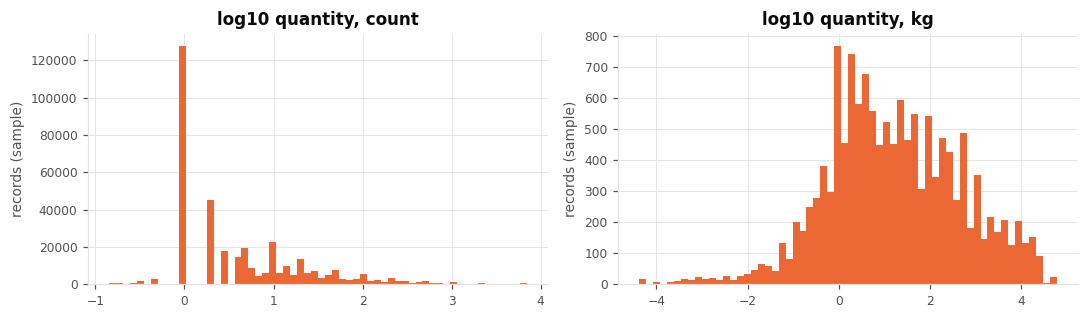

In [21]:
qty = Q("""SELECT CASE WHEN Unit IS NULL OR Unit = 'Number of specimens' THEN 'count' ELSE Unit END
                  AS u, log10(Quantity) AS lq
           FROM win WHERE Quantity > 0 USING SAMPLE 400000""")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, u in [(ax[0], "count"), (ax[1], "kg")]:
    x = qty.lq[qty.u == u]
    a.hist(x.clip(x.quantile(0.001), x.quantile(0.999)), bins=60, color=E.CITES_C)
    a.set_title(f"log10 quantity, {u}")
    a.set_ylabel("records (sample)")
fig.tight_layout()

In [22]:
Q("""SELECT count(*) FILTER (WHERE (Unit IS NULL OR Unit = 'Number of specimens')
                              AND Quantity <> floor(Quantity)) AS fractional_counts,
            count(*) FILTER (WHERE Quantity IS NULL) AS missing_quantity,
            count(*) FILTER (WHERE Quantity = 0) AS zero_quantity
     FROM win""")

,fractional_counts,missing_quantity,zero_quantity
0,158419,0,0


## Findings and what they imply

The counts the publishers state for CITES (guide §2) were reproduced: version and extraction date, file count, records per year, reporter split, Appendix N, blank origin and blank genus (86,568 here, where Appendix N is already excluded; the guide's 86,569 includes it). The findings below are what the data adds. For each one, the table gives what **CITES itself needs** before scoring, and what it **implies for alignment** with LEMIS (worked out in notebook 03). The rules that follow are recorded in [`DATA/ALIGNING_LEMIS_AND_CITES.md`](../../DATA/ALIGNING_LEMIS_AND_CITES.md), which cites each finding by number.

| # | Finding | Preprocessing CITES needs | Implication for alignment | Report |
|---|---|---|---|---|
| C1 | v2026.1, extracted 9 June 2026 (reports received by 5 May 2026): 59 CSVs, 29,170,051 records with unique `Id`, 1975–2026 | Record the version and extraction date; never mix versions | None | §3.1 |
| C2 | 20.96M animal records (plants have no `Class`); the 2015–2024 scoring window holds 8,247,093 | Select animals (`Class` not blank) in 2015–2024 | None | §3.1 |
| C3 | 2024 has ~15% fewer records than 2023 and 2025 is almost empty, because reports lag | Rank within each year; never read 2024–25 as a trend | None | §3.1 |
| C4 | One row = one permit line item **as reported by one Party**: 4,836,000 exporter-reported and 3,411,093 importer-reported. 72–80% of exporter-reported records have an importer-reported mirror, and only ~36% of mirror pairs agree on quantity | State the reporter type behind every count and share: use exporter-reported records (more complete) or pair the records | LEMIS has one reporter, CITES two: decide whether a ranking scores both halves of a pair (X1) | §3.1, §3.4 |
| C5 | Appendix II 93.8%, I 4.9%, III 1.2%; Appendix `N` (6,511) is not a CITES listing | Remove Appendix `N` | Ignore `N` in any appendix attached to LEMIS (X8) | §3.4 |
| C6 | Purpose is commercial in 90% of records for both reporter types; personal 3%, hunting trophy 3–4% | None | CITES resembles LEMIS's commercial subset, not its personal-luggage cases (L7, X10) | §3.3 |
| C7 | Source: wild 60%, captive-type (C, F, R, D) 38%, pre-Convention `O` 0.75%, unknown `U` 0.08%. `I` is mostly importer-reported (30,272 vs 2,684) and marks legal movement of previously seized items, not seizures | Treat source `I` / purpose `L` records as material already handled by enforcement, not trade to triage | CITES writes pre-Convention as `O`; whether LEMIS uses the same code is tested in notebook 03 (X3) | §3.3, §3.4 |
| C8 | 115 terms overall, 101 for animals, 81 in the window. *Leather products (small)* alone is 54.5% of window records and *live* 24.3%; Reptilia is 63% of records | None | The product vocabulary has to be mapped term by term onto groups shared with LEMIS, and the product mix differs sharply from LEMIS's (X5) | §3.4 |
| C9 | Units: blank (51.7%) and `Number of specimens` both mean a count; 14 unit values including `microgrammes`; 158,419 fractional "counts". Many terms come in several units (*specimens* 13, *bodies* 31.5% in kg) | Read a blank unit as a count; keep quantities apart by unit; log-transform | The unit map must cover every CITES unit, including `microgrammes` (X4); peer groups must include unit and comparable terms | §3.4 |
| C10 | 86,568 records have no `Genus`: 81,773 higher taxa written as `Taxon = "<name> spp."` (*Scleractinia spp.* 60,899, *Elephantidae spp.* 9,818) and 4,599 hybrids | Recover the higher taxon from the first word of `Taxon`, so these records are not pooled into one "no genus" group | LEMIS stores higher taxa differently, so one convention has to cover both (X7) | §3.4 |
| C11 | `Origin` blank in 33.4%; when present it equals the exporter only 0.3% of the time. Special country codes: `XX` unknown, `XV` various, `HS` from the sea | Read a blank origin as the exporter (direct trade); a filled origin effectively marks a re-export | LEMIS's special country codes have to map onto these (X9) | §3.4 |
| C12 | Purpose missing in 10,763 and source in 12,070 window records. The export permit ID is present in 96.8% of records; the import permit ID in only 18.1%, and the origin permit ID (re-exports) in 44.1% | Map missing codes to "unknown". Keep the export permit ID: it groups line items into consignments and links an exporter's record to the importer's record of the same permit (notebook 05) | LEMIS has no permit IDs, so they cannot be model features; permit-based evidence can only be used on the CITES side (ALIGNING §2.3) | §3.4 |
| C13 | The US is the importer in 24% of window records | None | US-imported CITES records give a direct check of the alignment against LEMIS (X11) | §3.4 |

### What CITES needs before scoring

1. Check the version and extraction date in the release notes, and that all 59 files are present (C1).
2. Select animals (`Class` not blank) in 2015–2024 (C2) and remove Appendix `N` (C5).
3. State the reporter type behind every count, and decide how mirror pairs are scored (C4).
4. Read a blank unit as a count, keep quantities apart by unit and log-transform them (C9).
5. Recover higher taxa from `Taxon` when `Genus` is blank (C10).
6. Read a blank origin as the exporter (C11).
7. Map missing purpose and source to "unknown" (C12).
8. Keep source `I` / purpose `L` records out of the ranking (C7).
9. Rank within each year (C3).

The steps that depend on LEMIS (code, unit, product, taxonomy and country mappings) are worked out in notebook 03.